# Pillar 1 walkthrough: is there real skill in a trading record?

This notebook walks through the full `trade-analytics` pipeline step by step, with the reasoning
behind each method. It uses only **public data**: the CC0 testing journal (422 BTC/ETH perpetual
trades reconstructed from Hyperliquid fills) and synthetic example journals.

| Step | Question | Method |
|---|---|---|
| 1 | Is the file usable? | Schema check and conversion |
| 2 | What does the record look like? | Descriptive statistics |
| 3 | Is the mean outcome really above zero? | iid, stationary and Bayesian bootstrap |
| 4 | Is the Sharpe ratio credible given fat tails? | Probabilistic Sharpe Ratio, MinTRL |
| 5 | Is the win rate above breakeven? | Beta-Binomial posterior |
| 6 | Which slices are real? | Holm and Benjamini-Hochberg |
| 7 | Where do the losses come from? | Loss concentration, size quartiles |
| 8 | How much should be risked? | Kelly with parameter uncertainty |
| 9 | What drawdowns should be expected? | Monte Carlo of the trade sequence |

All random procedures use fixed seeds, so every number reproduces.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from trade_analytics.bayes import (
    bayesian_bootstrap_mean,
    breakeven_win_rate,
    partial_pool_win_rates,
    win_rate_posterior,
)
from trade_analytics.bootstrap import bootstrap_mean
from trade_analytics.ingest import ConversionOptions, convert_journal
from trade_analytics.metrics import summarise
from trade_analytics.monte_carlo import drawdown_risk, max_drawdown, simulate_equity
from trade_analytics.multiple_testing import slice_tests
from trade_analytics.plotting import LIGHT as T
from trade_analytics.plotting import title, use
from trade_analytics.schema import validate_trades
from trade_analytics.sharpe import sharpe_summary
from trade_analytics.sizing import growth_rate, kelly_fraction, kelly_with_uncertainty

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
use(T)  # shared chart style (light theme in the notebook)
plt.rcParams["figure.figsize"] = (9, 3.6)

## 1. Is the file usable? Schema check and conversion

Every analysis consumes one **canonical** table (`trade_id, instrument, direction, entry_time,
exit_time, entry_price, exit_price, size, pnl`, plus optional `risk_amount`, `fees`, ...).
`validate_trades` checks it and reports *all* problems at once.

In [2]:
journal = pd.read_csv(
    ROOT / "data/testing_journal/testing_journal.csv", parse_dates=["entry_time", "exit_time"]
)
validate_trades(journal)
provenance = json.loads((ROOT / "data/testing_journal/provenance.json").read_text())
print(provenance["source"], "|", provenance["license"])
print("period:", provenance["period_utc"])
print("reconstruction diagnostics:", provenance["diagnostics"])
journal.head()

Kaggle: 'Historical Trade Data' (pradeepjswl) — Hyperliquid fills | CC0 1.0 Universal (public domain)
period: ['2024-03-13 14:45:00+00:00', '2025-05-01 06:12:00+00:00']
reconstruction diagnostics: {'fills': 7562, 'gaps_discarded': 2, 'skipped_until_flat': 0, 'flips_split': 1, 'trades': 422}


,trade_id,instrument,direction,entry_time,exit_time,entry_price,exit_price,size,pnl,fees,price_pnl,notional,max_position,n_fills,liquidated
0,T0001,ETH,long,2024-03-13 14:45:00+00:00,2024-03-13 19:19:00+00:00,"3,967.2103","4,010.5000",1.5126,61.2570,4.2235,65.4800,"6,000.8023",1.5126,8,False
1,T0002,ETH,long,2024-03-14 18:49:00+00:00,2024-03-14 23:51:00+00:00,"3,759.8081","3,887.0000",2.6606,331.3075,7.1208,338.4067,"10,003.3455",2.6606,6,False
2,T0003,ETH,long,2024-03-15 09:15:00+00:00,2024-03-16 00:56:00+00:00,"3,625.4661","3,763.7000",1.6535,224.3035,4.2763,228.5698,"5,994.7082",1.6535,3,False
3,T0004,ETH,long,2024-03-16 12:44:00+00:00,2024-03-17 17:22:00+00:00,"3,591.5161","3,620.1852",14.9845,391.8608,37.8223,429.5916,"53,817.0731",14.9845,19,False
4,T0005,ETH,long,2024-03-18 04:02:00+00:00,2024-03-25 15:57:00+00:00,"3,491.3920","3,577.5230",15.1268,"1,265.4909",37.4255,"1,302.8858","52,813.5889",15.1268,23,False


Real journals rarely arrive in canonical form. The converter maps other formats onto the schema
and records every decision. Here is a synthetic MetaTrader export: two columns are both called
`Price`, `Profit` excludes costs, `Commission` is negative, and one row is a non-trade
`balance` entry.

In [3]:
raw_mt4 = pd.read_csv(
    ROOT / "examples/alien_journals/mt4_export.csv",
    dtype=str,
    keep_default_na=False,
    na_values=[""],
)
raw_mt4

,Ticket,Open Time,Type,Size,Item,Price,S / L,T / P,Close Time,Price.1,Commission,Taxes,Swap,Profit
0,1001,2024.03.04 09:15:00,buy,1.00,eurusd,1.08510,1.08310,1.08910,2024.03.04 13:40:00,1.08790,-7.00,0.00,0.00,280.00
1,1002,2024.03.05 10:02:00,sell,0.50,gbpusd,1.27150,1.27450,1.26550,2024.03.05 16:20:00,1.27450,-3.50,0.00,0.00,-150.00
2,1003,2024.03.06 08:30:00,buy,2.00,eurusd,1.08900,1.08700,1.09300,2024.03.07 09:10:00,1.09200,-14.00,0.00,-4.20,600.00
3,1004,NaN,balance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.00
4,1005,2024.03.08 14:45:00,sell,1.00,eurusd,1.09400,1.09600,1.09000,2024.03.08 18:05:00,1.09550,-7.00,0.00,0.00,-150.00
5,1006,2024.03.11 07:55:00,buy,0.80,gbpusd,1.28100,1.27850,1.28600,2024.03.11 15:30:00,1.28480,-5.60,0.00,0.00,304.00


In [4]:
result = convert_journal(
    raw_mt4, ConversionOptions.from_preset("mt4", multiplier=100_000, drop_invalid=True)
)
print("\n".join(result.notes))
print("\nrows dropped:\n", result.row_issues.drop_duplicates("line").to_string(index=False))
result.trades

cost columns ['Commission', 'Taxes', 'Swap'] treated as signed cash flows (fee = -sum)
P&L column is gross: net P&L = P&L - fees
risk_amount derived from stop price
1 invalid rows dropped (listed below)

rows dropped:
  line                  problem
    5 direction not recognised


,trade_id,instrument,direction,entry_time,exit_time,entry_price,exit_price,size,pnl,risk_amount,stop_price,fees,notional
0,1001,eurusd,long,2024-03-04 09:15:00+00:00,2024-03-04 13:40:00+00:00,1.0851,1.0879,1.0000,273.0000,200.0000,1.0831,7.0000,"108,510.0000"
1,1002,gbpusd,short,2024-03-05 10:02:00+00:00,2024-03-05 16:20:00+00:00,1.2715,1.2745,0.5000,-153.5000,150.0000,1.2745,3.5000,"63,575.0000"
2,1003,eurusd,long,2024-03-06 08:30:00+00:00,2024-03-07 09:10:00+00:00,1.0890,1.0920,2.0000,581.8000,400.0000,1.0870,18.2000,"217,800.0000"
3,1005,eurusd,short,2024-03-08 14:45:00+00:00,2024-03-08 18:05:00+00:00,1.0940,1.0955,1.0000,-157.0000,200.0000,1.0960,7.0000,"109,400.0000"
4,1006,gbpusd,long,2024-03-11 07:55:00+00:00,2024-03-11 15:30:00+00:00,1.2810,1.2848,0.8000,298.4000,200.0000,1.2785,5.6000,"102,480.0000"


Trade 1001: gross profit 280, commission -7, so net P&L = 273. Risk is derived from the stop:
|1.08510 - 1.08310| x 1 lot x 100,000 = 200, so this trade made +1.37R.

## 2. What does the record look like?

The testing journal has no planned stop, so outcomes are measured as **return on notional**
(P&L / (entry price x size); ADR-0005). USD figures are shown alongside: the gap between the two
reveals how position sizing affected results.

In [5]:
x = (journal["pnl"] / journal["notional"]).to_numpy()
unit = summarise(x)
usd = summarise(journal["pnl"].to_numpy())
pd.DataFrame(
    {
        "return on notional": [
            unit.n_trades,
            unit.win_rate,
            unit.avg_win,
            unit.avg_loss,
            unit.payoff_ratio,
            unit.profit_factor,
            unit.expectancy,
        ],
        "USD": [
            usd.n_trades,
            usd.win_rate,
            usd.avg_win,
            usd.avg_loss,
            usd.payoff_ratio,
            usd.profit_factor,
            usd.expectancy,
        ],
    },
    index=[
        "trades",
        "win rate",
        "avg win",
        "avg loss",
        "payoff ratio",
        "profit factor",
        "expectancy",
    ],
)

,return on notional,USD
trades,422.0000,422.0000
win rate,0.9360,0.9360
avg win,0.0099,"1,233.3000"
avg loss,-0.0148,"-8,119.5471"
payoff ratio,0.6709,0.1519
profit factor,9.8144,2.2221
expectancy,0.0083,634.8951


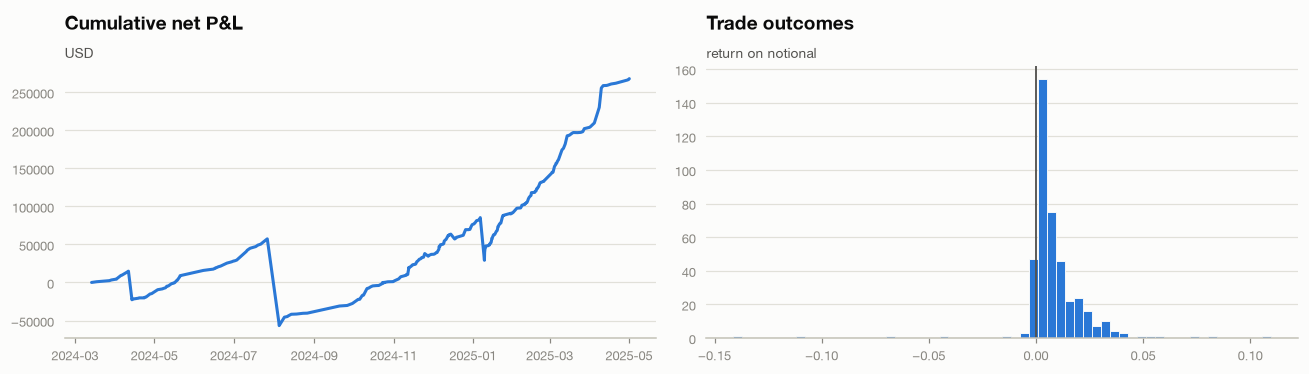

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(journal["exit_time"], journal["pnl"].cumsum())
title(axes[0], "Cumulative net P&L", "USD", T)
axes[1].hist(x, bins=60, edgecolor=T.surface, linewidth=0.6)
axes[1].axvline(0, color=T.ink2, lw=1.2)
title(axes[1], "Trade outcomes", "return on notional", T)
plt.tight_layout()

A 94% win rate, but the average loss is larger than the average win, and in USD the payoff ratio
collapses from 0.67 to 0.15. Keep that in mind; section 7 explains it.

**Expectancy identity:** mean = p x avg win - q x |avg loss|, with p and q measured over *all*
trades (scratch trades included in the denominator).

In [7]:
p, q = unit.n_wins / unit.n_trades, unit.n_losses / unit.n_trades
print(f"p*W - q*L = {p * unit.avg_win - q * abs(unit.avg_loss):.6f}   mean = {unit.expectancy:.6f}")

p*W - q*L = 0.008345   mean = 0.008345


## 3. Is the mean outcome really above zero?

A point estimate of 0.83% per trade says nothing about luck. The **bootstrap** resamples the
trades many times to see how much the mean could vary.

- **iid bootstrap:** resample individual trades with replacement.
- **Stationary bootstrap:** resample *blocks* of consecutive trades (random lengths, mean L),
  which keeps streaks intact. If outcomes cluster, this interval is wider.
- **Bayesian bootstrap:** random Dirichlet weights on the trades; each weighted mean is a
  posterior draw, which gives P(mean > 0) directly.

The p-value comes from the bootstrap distribution **shifted to mean zero** (imposing the null).

In [8]:
iid = bootstrap_mean(x, method="iid")
blk = bootstrap_mean(x, method="stationary")
bb = bayesian_bootstrap_mean(x)
pd.DataFrame(
    {
        "mean": [iid.mean, blk.mean, bb.mean()],
        "95% low": [iid.ci_low, blk.ci_low, np.quantile(bb, 0.025)],
        "95% high": [iid.ci_high, blk.ci_high, np.quantile(bb, 0.975)],
        "p (mean <= 0)": [iid.p_value, blk.p_value, np.mean(bb <= 0)],
    },
    index=["iid", f"stationary (L={blk.block_length:.1f})", "Bayesian"],
)

,mean,95% low,95% high,p (mean <= 0)
iid,0.0083,0.0068,0.0098,0.0001
stationary (L=7.5),0.0083,0.0066,0.0102,0.0001
Bayesian,0.0083,0.0067,0.0098,0.0000


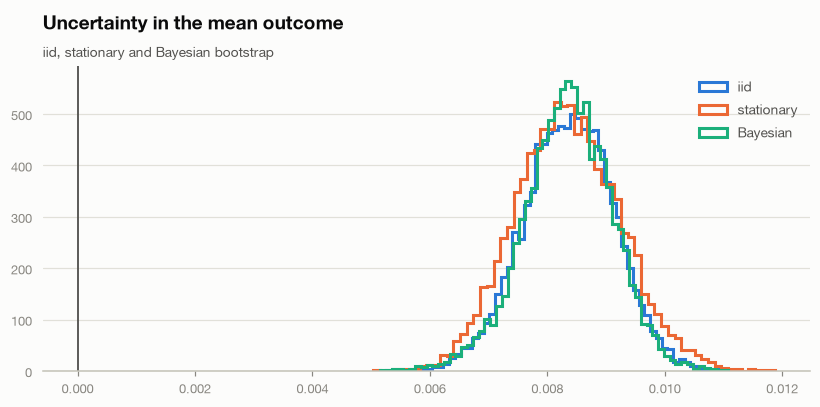

In [9]:
for draws, label in [(iid.samples, "iid"), (blk.samples, "stationary"), (bb, "Bayesian")]:
    plt.hist(draws, bins=60, histtype="step", lw=2, label=label)
plt.axvline(0, color=T.ink2, lw=1.2)
title(plt.gca(), "Uncertainty in the mean outcome", "iid, stationary and Bayesian bootstrap", T)
plt.legend();

All three agree: the interval is far from zero. The stationary interval is only slightly wider,
so streaks are mild.

**Sanity check (known answer):** on simulated data with a known mean, a 95% interval should
contain the truth in about 95% of samples.

In [10]:
true_mean, hits = 0.2, 0
for s in range(200):
    sample = np.random.default_rng(s).normal(true_mean, 1.0, 200)
    r = bootstrap_mean(sample, n_boot=500, seed=s)
    hits += r.ci_low <= true_mean <= r.ci_high
print(f"coverage: {hits / 200:.1%} (target 95%)")

coverage: 93.5% (target 95%)


## 4. Is the Sharpe ratio credible given fat tails?

The **Probabilistic Sharpe Ratio** (Bailey & López de Prado 2012) is the probability that the
true Sharpe exceeds a benchmark, accounting for skewness g3 and kurtosis g4:

$$\mathrm{PSR} = \Phi\!\left(\frac{(\widehat{SR}-SR^*)\sqrt{n-1}}{\sqrt{1-g_3\widehat{SR}+\frac{g_4-1}{4}\widehat{SR}^2}}\right)$$

The **Minimum Track Record Length** is how many trades are needed for PSR to reach 95%.
Negative skew and fat tails make the denominator bigger, so more trades are needed.

In [11]:
sh = sharpe_summary(x)
normal_trl = 1 + (1 + sh.sharpe**2 / 2) * (1.645 / sh.sharpe) ** 2
print(f"Sharpe per trade {sh.sharpe:.3f} | skew {sh.skew:.2f} | kurtosis {sh.kurtosis:.1f}")
print(
    f"PSR {sh.psr:.4f} | MinTRL {sh.min_trl:.1f} trades "
    f"(a normal distribution with the same Sharpe would need {normal_trl:.1f})"
)

Sharpe per trade 0.530 | skew -1.87 | kurtosis 35.8
PSR 1.0000 | MinTRL 43.7 trades (a normal distribution with the same Sharpe would need 12.0)


## 5. Is the win rate above breakeven?

For a payoff ratio b, the breakeven win rate is 1 / (1 + b). With a Beta(1, 1) prior and w wins
in n trades, the posterior for the win rate is Beta(1 + w, 1 + n - w).

In [12]:
post = win_rate_posterior(unit.n_wins, unit.n_trades)
be = breakeven_win_rate(unit.payoff_ratio)
lo, hi = post.interval()
print(f"posterior mean {post.mean:.2%}, 95% interval [{lo:.2%}, {hi:.2%}]")
print(f"breakeven win rate {be:.2%}; P(win rate > breakeven) = {post.prob_above(be):.4f}")

posterior mean 93.40%, 95% interval [90.85%, 95.56%]
breakeven win rate 59.85%; P(win rate > breakeven) = 1.0000


**Partial pooling.** Slices with few trades have noisy win rates. Empirical-Bayes shrinkage pulls
each slice towards the overall rate, more strongly when it has less data.

In [13]:
df = journal.assign(outcome=x)
grp = df.groupby(["instrument", "direction"])["outcome"]
pooled = partial_pool_win_rates(
    [" / ".join(k) for k in grp.groups], grp.apply(lambda s: (s > 0).sum()), grp.size()
)
pd.DataFrame({"trades": pooled.n, "raw": pooled.raw, "pooled": pooled.pooled}, index=pooled.groups)

,trades,raw,pooled
BTC / long,240.0000,0.9458,0.9361
BTC / short,97.0000,0.9588,0.9361
ETH / long,60.0000,0.8833,0.9360
ETH / short,25.0000,0.8800,0.9360


The pooled rates are all about 93.6%: the differences between slices are consistent with noise.

## 6. Which slices are real?

Slicing creates many tests, and some look significant by chance. **Holm** controls the chance of
*any* false positive; **Benjamini-Hochberg** controls the expected *share* of false positives.
Always report how many slices were tested.

In [14]:
slice_tests(df, "outcome", ["instrument", "direction"])

,slice,n,mean,t,p,p_holm,p_bh,significant_raw,significant_holm,significant_bh
0,BTC / long,240,0.0073,11.1403,0.0000,0.0000,0.0000,True,True,True
1,BTC / short,97,0.0066,9.0317,0.0000,0.0000,0.0000,True,True,True
2,ETH / long,60,0.0135,3.0859,0.0015,0.0015,0.0015,True,True,True
3,ETH / short,25,0.0130,4.6749,0.0000,0.0001,0.0001,True,True,True


## 7. Where do the losses come from?

The USD payoff ratio (0.15) is much worse than the per-unit one (0.67). That points at sizing:
the large losses happened on large positions.

In [15]:
losses = journal.loc[journal["pnl"] < 0, "pnl"]
top5 = journal.nsmallest(5, "pnl")
print(f"5 largest losses = {top5['pnl'].sum() / losses.sum():.1%} of all USD losses")
print(
    f"total P&L ${journal['pnl'].sum():,.0f}; without the worst trade "
    f"${journal['pnl'].sum() - journal['pnl'].min():,.0f}"
)
top5[["trade_id", "instrument", "direction", "entry_time", "notional", "pnl"]]

5 largest losses = 97.6% of all USD losses
total P&L $267,926; without the worst trade $376,993


,trade_id,instrument,direction,entry_time,notional,pnl
71,T0072,ETH,long,2024-07-26 21:25:00+00:00,"772,459.6859","-109,067.1608"
224,T0225,BTC,long,2025-01-06 17:01:00+00:00,"812,366.2362","-56,114.5202"
22,T0023,ETH,long,2024-04-11 09:57:00+00:00,"346,103.9528","-37,563.5046"
204,T0205,BTC,short,2024-12-14 23:31:00+00:00,"1,259,798.0510","-6,418.0908"
73,T0074,ETH,long,2024-08-04 18:09:00+00:00,"117,619.8855","-4,859.8801"


In [16]:
quartile = pd.qcut(journal["notional"], 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
df.assign(quartile=quartile).groupby("quartile", observed=True).agg(
    trades=("outcome", "size"),
    mean_return=("outcome", "mean"),
    win_rate=("outcome", lambda s: (s > 0).mean()),
    usd_pnl=("pnl", "sum"),
)

,trades,mean_return,win_rate,usd_pnl
quartile,,,,
Q1 small,106,0.0091,0.9434,"16,256.0460"
Q2,105,0.0103,0.9524,"43,123.4464"
Q3,105,0.0100,0.9238,"107,497.6116"
Q4 large,106,0.0041,0.9245,"101,048.6130"


The largest-position quartile earned less than half the per-trade return of the others. The
pattern is suggestive (rank correlation -0.08, p = 0.12), not conclusive.

## 8. How much should be risked? Kelly with uncertainty

Each trade multiplies equity by (1 + f x). Kelly picks the f that maximises expected log growth
g(f) = E[log(1 + f x)]. Here f is **leverage** (notional / equity).

**Known answer first:** for a coin that wins +1 with p = 0.6 and loses -1 otherwise,
f* = p - q / b = 0.2.

In [17]:
coin = np.array([1.0] * 60 + [-1.0] * 40)
print("Kelly on the coin:", round(kelly_fraction(coin), 4))

Kelly on the coin: 0.2


full Kelly 6.72x | posterior 5-95%: 6.02-7.06x
wipe-out bound from the worst trade (-14.12%): 7.08x


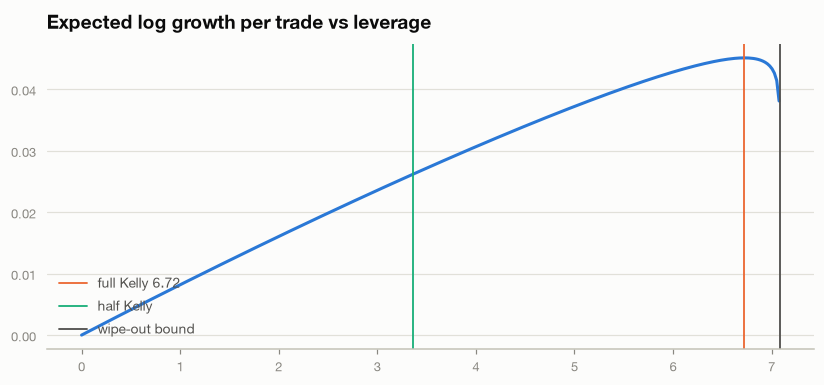

In [18]:
k = kelly_with_uncertainty(x)
bound = 1 / -x.min()
print(
    f"full Kelly {k.point:.2f}x | posterior 5-95%: {k.quantile(0.05):.2f}-{k.quantile(0.95):.2f}x"
)
print(f"wipe-out bound from the worst trade ({x.min():.2%}): {bound:.2f}x")
f_grid = np.linspace(0, bound * 0.999, 300)
plt.plot(f_grid, [growth_rate(x, f) for f in f_grid])
plt.axvline(k.point, color=T.series[1], lw=1.2, label=f"full Kelly {k.point:.2f}")
plt.axvline(k.point / 2, color=T.series[2], lw=1.2, label="half Kelly")
plt.axvline(bound, color=T.ink2, lw=1.2, label="wipe-out bound")
title(plt.gca(), "Expected log growth per trade vs leverage", "", T)
plt.legend(loc="lower left");

Full Kelly sits just below the leverage at which a repeat of the worst trade would wipe out the
account. It is "optimal" only if no worse trade ever happens, and with kurtosis near 36 one
eventually will. Half Kelly keeps

In [19]:
print(
    f"{growth_rate(x, k.point / 2) / growth_rate(x, k.point):.0%} of full-Kelly growth here "
    "(about 75% in the textbook quadratic approximation)"
)

58% of full-Kelly growth here (about 75% in the textbook quadratic approximation)


## 9. What drawdowns should be expected?

The historical order of trades is one draw among many. Resampling the sequence 10,000 times shows
the range of drawdowns the same edge could have produced at different leverage levels.

In [20]:
risk = drawdown_risk(x, fractions=[1, 2, 3, round(k.point / 2, 2)], n_paths=10_000).table
risk

,fraction,median_final_equity,median_max_dd,p95_max_dd,p_ruin,p_dd_ge_20,p_dd_ge_30,p_dd_ge_50
0,1.0000,32.1200,0.1412,0.2105,0.0000,0.0670,0.0013,0.0000
1,2.0000,905.8427,0.2824,0.4067,0.0000,0.8609,0.1755,0.0042
2,3.0000,"22,158.9788",0.4236,0.5815,0.0022,0.9461,0.8603,0.1121
3,3.3600,"67,337.0032",0.4744,0.6385,0.0041,0.9461,0.8629,0.1737


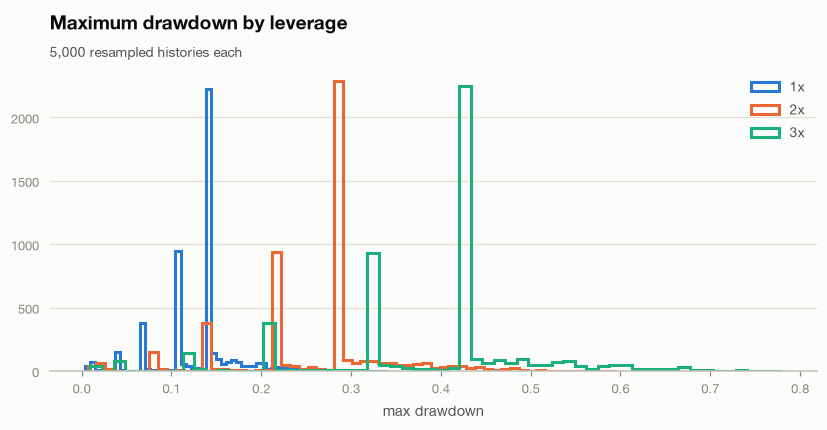

In [21]:
for f in [1, 2, 3]:
    dd = max_drawdown(simulate_equity(x, f, n_paths=5_000))
    plt.hist(dd, bins=60, histtype="step", lw=2, label=f"{f}x")
title(plt.gca(), "Maximum drawdown by leverage", "5,000 resampled histories each", T)
plt.xlabel("max drawdown")
plt.legend();

## Conclusions

1. The edge is statistically clear: mean +0.83% per trade, confidence interval well above zero,
   PSR above 0.999, and every slice survives multiple-testing correction.
2. The record is strongly negatively skewed: many small wins, rare large losses. The five
   largest losses are about 98% of all USD losses, and they happened on large positions.
3. Statistical significance does not make aggressive sizing safe. Full Kelly is pinned against
   the wipe-out bound; a risk manager would cap leverage well below half Kelly and investigate
   why the largest positions performed worst.

**Caveats:** one account, one bull-market period, an account chosen from a curated dataset, and
out-of-sample losses can exceed the worst one observed.

**More:** [write-up](../docs/projects/pillar-1/PROJECT.md) ·
[full report](../reports/testing_journal/REPORT.md) ·
[decision records](../docs/decisions/) · [learning notes](../docs/learning/)